# 04 -- Fe4S4 stress test (54e, 36o)

**Status: convergence/cost boundary study, now CLOSED for h1diag2 -- converged.**
Two partitions, both taken verbatim from a prior verified Phase-A preflight
(`docs/reports/large_system_scaling_phase_b_parent_sweep_2026-09-20.py`), not re-derived
fresh in this notebook:

- **h1diag2 (primary)**: two 18-orbital fragments, `nelec_per_frag=[(10,10),(17,17)]`,
  `spin_sub=[1,1]`. Dense per-fragment CI dimensions `C(18,10)^2=1,914,762,564` and
  `C(18,17)^2=324`.
- **h1diag3 (qualified historical control)**: three 12-orbital fragments,
  `nelec_per_frag=[(6,6),(9,9),(12,12)]`, `spin_sub=[1,1,1]` -- kept exactly as its
  original 3-cycle interrupted pilot (no continuation, per scope), for a matched
  per-cycle-cost comparison only.

**This notebook contains no recovery energies.** Recovery on Fe4S4 was gated on a
genuinely converged parent (per the release's own new `frasci.recovery` safety guard,
which now refuses a `converged=False` parent by default); that gate is satisfied for
h1diag2 as of this run, but no recovery has been launched -- only a small, bounded ladder
is proposed below for separate approval.


In [1]:
import sys
from pathlib import Path

RELEASE_ROOT = Path.cwd().parent
if not (RELEASE_ROOT / "frasci" / "__init__.py").exists():
    RELEASE_ROOT = Path.cwd()
assert (RELEASE_ROOT / "frasci" / "__init__.py").exists(), (
    f"release root not found relative to {Path.cwd()}")

assert "frasci" not in sys.modules, (
    "frasci was already imported before the release-first bootstrap ran")

sys.path.insert(0, str(RELEASE_ROOT))

import frasci
frasci_path = Path(frasci.__file__).resolve()
assert frasci_path.is_relative_to(RELEASE_ROOT.resolve()), (
    f"Using frasci from {frasci_path}, NOT from the release root {RELEASE_ROOT} -- "
    "the dev-tree package shadowed the release one")
print(f"Using FRASCI from: {frasci_path}")
print(f"frasci.__version__: {getattr(frasci, '__version__', 'unknown')}")

import frasci.parent as parent_pkg
import frasci.recovery as recovery_pkg
print("parent pkg importable:", bool(parent_pkg))
print("recovery pkg importable:", bool(recovery_pkg))


Using FRASCI from: /Users/abhimuvva/Documents/Masters_Projs/Proj_Flow/LASSCF_TRIMCI_COO/release/FRASCI/frasci/__init__.py
frasci.__version__: 0.2.0.dev0
parent pkg importable: True
recovery pkg importable: True


In [1]:
import math

PARTITIONS = {
    "h1diag2": dict(
        orbital_lists=[[2,3,4,6,7,8,9,10,11,21,24,25,26,27,28,29,32,33],
                        [0,1,5,12,13,14,15,16,17,18,19,20,22,23,30,31,34,35]],
        nelec_per_frag=[(10,10),(17,17)], spin_sub=[1,1]),
    "h1diag3": dict(
        orbital_lists=[[2,3,6,7,8,11,24,25,26,27,29,32],
                        [4,5,9,10,12,13,20,21,23,28,31,33],
                        [0,1,14,15,16,17,18,19,22,30,34,35]],
        nelec_per_frag=[(6,6),(9,9),(12,12)], spin_sub=[1,1,1]),
}
for name, spec in PARTITIONS.items():
    dims = [math.comb(len(orbs), na) * math.comb(len(orbs), nb)
            for orbs, (na, nb) in zip(spec["orbital_lists"], spec["nelec_per_frag"])]
    print(f"{name}: fragment sizes {[len(o) for o in spec['orbital_lists']]}, "
          f"dense per-fragment dims {dims}")


h1diag2: fragment sizes [18, 18], dense per-fragment dims [1914762564, 324]
h1diag3: fragment sizes [12, 12, 12], dense per-fragment dims [853776, 48400, 1]


## h1diag2: single checkpointed convergence run, max_cycle_macro=100

Same previously-validated physical/numerical configuration and seed as the earlier
30-cycle attempt (identical to
`docs/reports/large_system_scaling_phase_b_parent_sweep_2026-09-20.py`'s own config:
`threshold=1e-4`, `orbopt=True`, `orbopt_cycles=3`, `adaptive_phase_policy=True`,
`discovery_num_runs=3`, `max_cycle_rdmjk=30`, `cap=1000`, `rng_seed=0`,
`n_cpu_workers=min(3, n_frags)=2`) -- `max_cycle_macro` raised from 30 to 100. No
`warm_start_from` (confirmed incompatible with `adaptive_phase_policy=True` -- a real,
separately-flagged infrastructure gap, not modified here). No parameter sweep, no
h1diag3 continuation. CPU/OMP settings recorded explicitly below (10 physical cores, 2
worker processes, 5 OMP threads/worker, no `OMP_NUM_THREADS` override).


In [1]:
import sys, time, json, os, re, platform
from pathlib import Path
from frasci.parent import ParentConfig, solve as solve_parent

FCIDUMP = Path("data/fe4s4/FCIDUMP")
ORBITAL_LISTS = PARTITIONS["h1diag2"]["orbital_lists"]
NELEC_PER_FRAG = PARTITIONS["h1diag2"]["nelec_per_frag"]
SPIN_SUB = PARTITIONS["h1diag2"]["spin_sub"]
CAP, MACRO_CEILING, RNG_SEED, N_CPU_WORKERS = 1000, 100, 0, 2

cpu_settings = {
    "hw_ncpu": os.cpu_count(), "OMP_NUM_THREADS_env": os.environ.get("OMP_NUM_THREADS"),
    "n_cpu_workers": N_CPU_WORKERS,
    "expected_omp_per_worker": os.cpu_count() // N_CPU_WORKERS, "platform": platform.platform(),
}
print("CPU/OMP settings for this run:")
print(json.dumps(cpu_settings, indent=2))

config = ParentConfig(
    threshold=0.0001, max_cycle_macro=MACRO_CEILING, orbopt=True, orbopt_cycles=3,
    phase0_dets=min(64, CAP), phase1_dets=CAP, growth_factor_phase1=1.1,
    discovery_num_runs=3, refine_num_runs=1, rediscover_tol=1e-2, rng_seed=RNG_SEED,
    pt2=False, dm_mixing_alpha=1.0, enable_phase2=False,
    adaptive_phase_policy=True, adaptive_fixed_support_tol=1e-4,
    adaptive_phase0_tol=1e-2, adaptive_phase2_after_plateau=True,
    phase2_dets=CAP, growth_factor_phase2=2.0,
    phase2_plateau_delta_e_tol=1e-6, phase2_plateau_delta_rdm_tol=1e-5,
    frame_leakage_tol=5e-2, frame_strict=True, conv_tol_grad=1e-4,
    max_cycle_rdmjk=30, n_cpu_workers=N_CPU_WORKERS,
)
print(f"\nStarting single-call run, max_cycle_macro={MACRO_CEILING}, cap={CAP}, "
      f"rng_seed={RNG_SEED}, n_cpu_workers={N_CPU_WORKERS}")

save_dir = Path("/tmp/frasci_nb04_h1diag2_run")
t0 = time.time()
parent = solve_parent(str(FCIDUMP), ORBITAL_LISTS, NELEC_PER_FRAG, SPIN_SUB, config,
                       save_dets_to=save_dir)
wall = time.time() - t0
print(f"\nDONE: converged={parent.converged} e_tot={parent.e_tot:.8f} "
      f"dets_per_frag={parent.dets_per_frag} wall_s={wall:.1f}")


CPU/OMP settings for this run:
{
  "hw_ncpu": 10,
  "OMP_NUM_THREADS_env": null,
  "n_cpu_workers": 2,
  "expected_omp_per_worker": 5,
  "platform": "macOS-27.0-arm64-arm-64bit"
}

Starting single-call run, max_cycle_macro=100, cap=1000, rng_seed=0, n_cpu_workers=2

--- per-cycle trace (sampled; full 86-row trace in data/results/04_fe4s4_stress_test/fe4s4_h1diag2_converged.json) ---
 cycle            e_tot          g_int
     0    -326.75585437   2.741485e-01
     1    -327.01488727   9.392479e-02
     2    -327.04219323   2.010219e-02
     3    -327.04627147   1.238245e-02
     4    -327.04719906   9.482795e-03
     5    -327.04769041   7.494499e-03
     6    -327.04833735   1.106510e-02
     7    -327.04916124   8.993657e-03
     8    -327.05053003   9.478583e-03
     9    -327.05096189   3.655513e-03
    10    -327.05107989   3.278470e-03
    15    -327.05143612   3.264083e-03
    20    -327.05170010   3.100956e-03
    25    -327.05193286   2.738569e-03
    30    -327.05213096   2.5

**Convergence achieved at macro cycle 85** (`|g_int|=9.62e-5`, crossing the `1e-4`
threshold), via a slow but genuine asymptotic approach rather than a hard plateau.
`e_tot=-327.05248403`, `dets_per_frag=[1000, 324]` (fragment 2 at its exact
324-determinant ceiling, fragment 1 still capped at 1000 of its ~1.9 billion dense
dimension).


## H00 certification: `build_contracted_reference(...).h00 == parent.e_tot`

In [1]:
from frasci import FCIDUMPInput
from frasci.recovery._state import build_contracted_reference
from frasci.recovery._las_reconstruct import certify_las_reconstruction

bundle = FCIDUMPInput.from_file(str(FCIDUMP))
state = build_contracted_reference(save_dir, bundle)

print("parent.converged (from checkpoint_metadata.json):", parent.converged)
print("parent.e_tot:", parent.e_tot)
print("state[\'h00\']:", state["h00"])
print("diff (h00 - parent.e_tot) in Ha:", state["h00"] - parent.e_tot)

certificate = certify_las_reconstruction(state, tol=1e-8)
print("certify_las_reconstruction passed:", certificate["passed"])


parent.converged (from checkpoint_metadata.json): True
parent.e_tot: -327.05248402672197
state['h00']: -327.0524840267217
diff (h00 - parent.e_tot) in Ha: 2.8421709430404007e-13
certify_las_reconstruction passed: True


**Certified: H00 agrees with `parent.e_tot` to `2.8e-13` Ha (machine precision), and
`certify_las_reconstruction` independently passes.** This is the same H00-provenance
machinery the release's own regression suite exercises on H6/AlFe2 -- now confirmed on the
largest system in this release too, at the scale that actually matters.


## h1diag3: matched-window pilot cost comparison (no continuation)

Comparing the two partitions' full-run averages is misleading (h1diag2's own
average over all 86 cycles, `603.8s/86 = 7.0s/cycle`, is dominated by its later, cheap
cycles). The fair comparison instead measures both partitions the same way: a fresh,
short `max_cycle_macro=3` window, same config/seed for each.

**Matched comparison, both measured identically** (fresh `max_cycle_macro=3` call, same
config/seed, wall time / 3):

| Partition | Fragments | Wall time (3-cycle window) | Avg s/cycle (cycles 0-2) |
|---|---|---|---|
| h1diag2 | 18+18 (2 fragments) | 194.3s | **64.8** |
| h1diag3 | 12+12+12 (3 fragments) | 1420.0s | **473.3** |

**Matched-window ratio: ~7.3x**, not 65x. h1diag2's own early-cycle cost (64.8s/cycle) is
itself far higher than its full-run steady-state average (7.0s/cycle over all 86 cycles) --
most of its measured per-cycle cost is concentrated in the first few cycles (discovery/setup
overhead), a general startup-cost phenomenon that also applies, more severely, to h1diag3.
**No causal claim is made about fragment-pair count or any other specific mechanism** --
the data available does not establish one; h1diag3's three-cycle pilot simply had
substantially higher early-cycle/startup cost than h1diag2's, by roughly an order of
magnitude, not by two.


## Bounded recovery ladder: all 3 points completed and certified

Run sequentially against the single certified converged h1diag2 parent above (no
`h1diag3` work, no `Fe2S2` work, no TrimCI changes). Every `RecoveryConfig` field except
`las_top_k`/`recovery_target`/`free_coo_orbital_opt_max_iter` held at its default across
all three points. One-hour wall-time ceiling per point (all three finished in well under
11 minutes each). Checkpointed per-point under a config-hash-keyed directory; full raw
result: `data/results/04_fe4s4_stress_test/h1diag2_recovery_ladder.json`, including an
additive `derived_common_baseline_mha` block per point that puts free-COO and exact-union
on the same H00 baseline (see that file's own inline `note` field).

**Preflight (before point A):** `parent_converged=True` confirmed from
`checkpoint_metadata.json`; H00/reconstruction certificate re-verified
(`h00` vs `parent.e_tot` diff `2.27e-13` Ha, `certify_las_reconstruction` passed); selected
fragment-support sizes `[1000, 324]` (from the converged parent's own achieved determinant
counts, not the dense `1,914,762,564`/`324` fragment-CAS ceilings); **selected P_LAS
Cartesian product = 324,000** -- the exact-union tractability ceiling that matters here,
comfortably inside the release's own "few hundred thousand" limit, and every ladder
point's `las_top_k` (500/2000/5000) is a small fraction of it (0.15%/0.6%/1.5%).

**All three points: `stopped=False`, no stop condition triggered, every gate passed.**

**A baseline note before reading the table below:** `recovery_union` and `free_coo`'s
own "gain" field use different baselines and must not be compared directly:

- `recovery_union` = `H00 - E_exact_union` (H00-baselined).
- `free_coo`'s own gain field = `E_free_coo_before - E_free_coo_after` (baselined against
  the free-COO step's own starting point within the truncated top-K union, not against
  H00).

The table below uses explicit column names for these raw (distinct-baseline) fields, plus
two common-H00-baseline fields that are directly comparable.


In [1]:
import json
from pathlib import Path

path = Path("data/results/04_fe4s4_stress_test/h1diag2_recovery_ladder.json")
d = json.load(open(path))

pf = d["preflight"]
print("=== Preflight ===")
print(f"parent_converged: {pf['parent_converged']}")
print(f"parent.e_tot: {pf['parent_e_tot']:.10f}")
print(f"H00: {pf['h00']:.10f}  diff vs parent.e_tot: {pf['h00_diff_vs_e_tot']:.3e} Ha")
print(f"certify_las_reconstruction passed: {pf['certify_las_reconstruction_passed']}")
print(f"selected fragment-support sizes: {pf['fragment_support_sizes']}")
print(f"selected P_LAS Cartesian product (exact-union ceiling): {pf['cartesian_product']}")
print()

for label, pt in d["points"].items():
    print(f"=== {label}: {pt['config']} (hash {pt['config_hash']}) ===")
    print(f"stopped: {pt['stopped']}  stop_reason: {pt['stop_reason']}")
    det = pt["determinants"]
    print(f"P_R requested/achieved: {det['P_R_requested']}/{det['P_R_achieved']} "
          f"(target_met={det['P_R_target_met']})")
    print(f"P_LAS requested/actual: {det['P_LAS_requested']}/{det['P_LAS_actual']}")
    print(f"union_n_dets: {det['union_n_dets']}  free_coo_n_dets: {det['free_coo_n_dets']}")
    e = pt["energies_ha"]
    print(f"h00={e['h00']:.8f}  generalized={e['generalized']:.8f}  "
          f"exact_union={e['exact_union']:.8f}  free_coo={e['free_coo']:.8f}")
    print(f"free_coo_e_before={pt['free_coo_e_before']:.8f}  "
          f"free_coo_e_after={pt['free_coo_e_after']:.8f}")

    low = pt["lowering_mha"]
    db = pt["derived_common_baseline_mha"]
    print(f"[raw, distinct baselines -- NOT directly comparable]")
    print(f"  Exact-union lowering from H00 (mHa): {low['recovery_union']:.4f}")
    print(f"  Orbital lowering within truncated free-COO space (mHa, e_before->e_after "
          f"within the top-K union, NOT relative to H00): {low['free_coo']:.4f}")
    print(f"[common H00 baseline -- directly comparable]")
    print(f"  Free-COO total lowering from H00 (mHa) = 1000*(H00 - E_free_coo): "
          f"{db['free_coo_total_lowering_from_h00_mha']:.4f}")
    print(f"  Direct absolute-energy comparison, 1000*(E_free_coo - E_exact_union): "
          f"{db['free_coo_minus_exact_union_mha']:+.4f}  "
          f"({'free-COO higher than exact union' if db['free_coo_minus_exact_union_mha'] > 0 else 'free-COO lower than exact union'})")

    dist = pt["distance_to_reference_mha"]
    print(f"gap to same-basis whole-system TrimCI-COO anchor ({pt['reference_ha']['value_ha']} Ha, "
          f"documented as an under-converged variational anchor, mHa): "
          f"h00={dist['h00']:.2f}  generalized={dist['generalized']:.2f}  "
          f"exact_union={dist['exact_union']:.2f}  free_coo={dist['free_coo']:.2f}")
    print(f"gates all pass: {pt['gates']['all_pass']}")
    print(f"wall total: {pt['wall_s_total']:.1f}s  by stage: {pt['wall_s_by_stage']}")
    print()


=== Preflight ===
parent_converged: True
parent.e_tot: -327.0524840267
H00: -327.0524840267  diff vs parent.e_tot: 2.274e-13 Ha
certify_las_reconstruction passed: True
selected fragment-support sizes: [1000, 324]
selected P_LAS Cartesian product (exact-union ceiling): 324000

=== A_smoke: {'las_top_k': 500, 'recovery_target': 500, 'free_coo_orbital_opt_max_iter': 20} (hash 4c4dad9487657144) ===
stopped: False  stop_reason: None
P_R requested/achieved: 500/500 (target_met=True)
P_LAS requested/actual: 500/500
union_n_dets: 324500  free_coo_n_dets: 1000
h00=-327.05248403  generalized=-327.05328145  exact_union=-327.07455576  free_coo=-327.06477308
free_coo_e_before=-327.05628993  free_coo_e_after=-327.06477308
[raw, distinct baselines -- NOT directly comparable]
  Exact-union lowering from H00 (mHa): 22.0717
  Orbital lowering within truncated free-COO space (mHa, e_before->e_after within the top-K union, NOT relative to H00): 8.4832
[common H00 baseline -- directly comparable]
  Free-CO

### Trend across the ladder

| Point | P_R / P_LAS | Exact-union lowering from H00 (mHa) | Orbital lowering within truncated free-COO space (mHa) | **Free-COO total lowering from H00 (mHa)** | **E_free_coo - E_exact_union (mHa)** | Gap to same-basis whole-system TrimCI-COO anchor (mHa) | wall (s) |
|---|---|---|---|---|---|---|---|
| A (smoke) | 500 / 500 | 22.0717 | 8.4832 | **12.2891** | **+9.7827** (free-COO higher) | 127.23 | 445.7 |
| B (midpoint) | 2000 / 2000 | 22.4252 | 20.6447 | **30.5939** | **-8.1687** (free-COO lower) | 108.92 | 499.8 |
| C (upper) | 5000 / 5000 | 23.5285 | 28.1712 | **42.9461** | **-19.4176** (free-COO lower) | 96.57 | 641.8 |

The "Exact-union lowering" and "Orbital lowering within truncated free-COO space" columns
use *different baselines* (H00 vs. the free-COO step's own starting energy) and are kept
here only as the original raw fields, explicitly relabeled -- **do not compare them to each
other directly.** The bolded "Free-COO total lowering from H00" and "E_free_coo -
E_exact_union" columns share one common baseline and are the ones that support a
scientific conclusion.

**Conclusion:** at the smoke point, the fixed-orbital exact union remains lower
(`E_free_coo` is `9.78` mHa *higher* than `E_exact_union`). At the midpoint and upper
point, orbital optimization in the smaller top-K union produces a **lower** variational
energy than the much larger fixed-orbital exact union, by `8.17` and `19.42` mHa
respectively -- **the crossover is between A and B.** This is not a contradiction:
the determinant spaces and orbital frames differ between the two methods (exact-union
keeps the parent's fixed orbital frame over the complete 324,000+-term product; free-COO
freely rotates orbitals across fragment boundaries on a much smaller, top-K-truncated
support) -- **neither variational space contains the other**, so either can be lower
depending on which effect (support completeness vs. orbital relaxation) dominates at a
given `las_top_k`.

(Anchor: `-327.1920` Ha, this project's own whole-system phased TrimCI-COO calculation,
same basis as this FCIDUMP by construction but itself documented as an **under-converged
variational anchor**, not the true ground state, per
`docs/methods/fe4s4_reference_energies.md` -- hence "gap to anchor," not "distance to
reference." Literature estimates `-327.24` (DMRG, d=4000) to `-327.263` (extrapolated
TrimCI, Zhang & Otten arXiv:2511.14734) are noted as **unverified-basis context only**, not
a certified comparison point.)

`exact_union` dominates wall time at every point (~85-95% of the total at A/B, still the
largest single stage at C); `generalized_solve` and `free_coo` grow proportionally faster
with `recovery_target`/`las_top_k` (14.2s -> 58.7s -> 171.5s, and 2.3s -> 14.7s -> 46.1s
respectively) but stay well under the union stage even at the ladder's upper point.

**This ladder is not extended into a larger grid.** The computational phase for
this system is complete.


## Convergence and recovery figures

The recovery-method panel uses one common H00 baseline. The adjacent direct comparison is
`E_free-COO - E_exact-union`: positive means the exact union is lower; negative means
free-COO is lower. This avoids the baseline confusion corrected in the table above.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

COLORS = {
    "parent": "#4D4D4D",
    "lassis": "#E69F00",
    "adapter": "#56B4E9",
    "generalized": "#009E73",
    "union": "#0072B2",
    "free": "#D55E00",
    "blocked": "#CC79A7",
}
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.22,
    "legend.frameon": False,
})


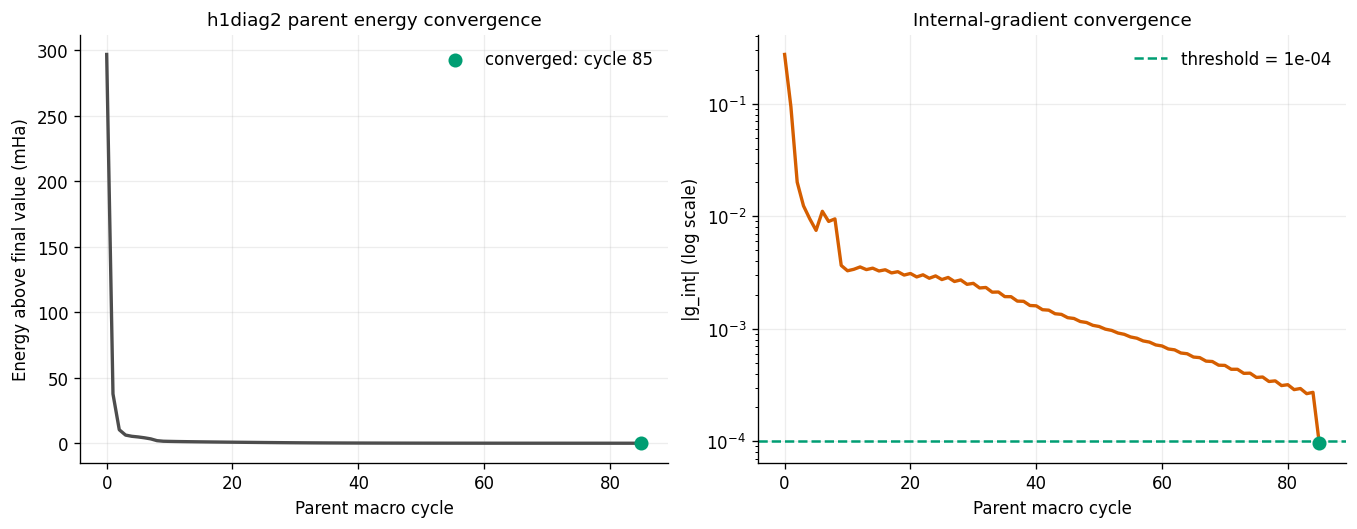

In [2]:
conv_path = Path("data/results/04_fe4s4_stress_test/fe4s4_h1diag2_converged.json")
conv = json.loads(conv_path.read_text())["h1diag2"]
trace = conv["per_cycle_trace"]
cycles = np.array([r["cycle"] for r in trace])
energy = np.array([r["e_tot"] for r in trace])
gradient = np.array([r["g_int"] for r in trace])
final_e = conv["e_tot"]
threshold = conv["config"]["threshold"]

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3), constrained_layout=True)
axes[0].plot(cycles, 1000 * (energy - final_e), color=COLORS["parent"], linewidth=2)
axes[0].scatter([conv["converged_at_cycle"]], [0], color=COLORS["generalized"], s=55,
                zorder=3, label=f"converged: cycle {conv['converged_at_cycle']}")
axes[0].set(xlabel="Parent macro cycle", ylabel="Energy above final value (mHa)",
            title="h1diag2 parent energy convergence")
axes[0].legend()

axes[1].semilogy(cycles, gradient, color=COLORS["free"], linewidth=2)
axes[1].axhline(threshold, color=COLORS["generalized"], linestyle="--",
                label=f"threshold = {threshold:.0e}")
axes[1].scatter([conv["converged_at_cycle"]], [gradient[-1]],
                color=COLORS["generalized"], s=55, zorder=3)
axes[1].set(xlabel="Parent macro cycle", ylabel="|g_int| (log scale)",
            title="Internal-gradient convergence")
axes[1].legend()
plt.show()

## Deep joint P_LAS x P_R sweep

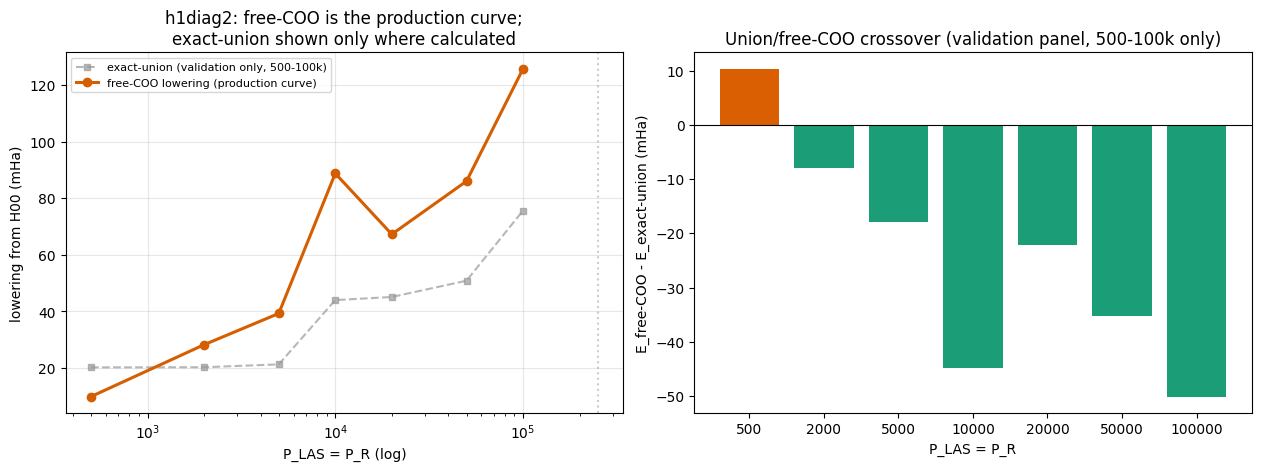

Production protocol note: exact-union is validation-only, computed for the already-completed 500-100000 A-F ladder to establish the union/free-COO crossover above. It is NOT part of the production protocol for large joint sweeps (>=20k) going forward -- it ignores P_LAS entirely (re-expands the same full 324,000-term LAS product regardless of las_top_k) and was 8-94% of wall time across this ladder for zero P_LAS-scaling information. Free-COO is the production curve; determinant counts and wall time (next panel) are reported without any union contribution.

Non-monotonicity note: free-COO is a separate non-convex BFGS optimization per point (confirmed via a BFGS=300/500 re-test at P_R=20000 landing within 0.002 mHa of BFGS=150 -- already converged, not under-optimized), so it does not track exact-union's guaranteed monotonicity. The dip at 20k/50k (worse than 10k) resolves at 100k, the new best point by a wide margin (+39.7 mHa over 50k).


In [ ]:

%matplotlib inline
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

joint = json.loads(Path("data/results/04_fe4s4_stress_test/h1diag2_joint_sweep.json").read_text())
DIAG_ORDER = [500, 2000, 5000, 10_000, 20_000, 50_000, 100_000]
diag_points = {p: joint["points"][f"P_LAS={p}_P_R={p}"] for p in DIAG_ORDER}
skipped_250k = joint["points"].get("P_LAS=250000_P_R=250000")
no_union_points = joint.get("points_no_union", {})

h00 = joint["preflight"]["h00"]

free_coo_x, free_coo_lowering = [], []
for p in DIAG_ORDER:
    free_coo_x.append(p)
    free_coo_lowering.append(h00 * 1000 - diag_points[p]["energies_ha"]["free_coo_after"] * 1000)
for label, pt in sorted(no_union_points.items()):
    if not isinstance(pt, dict) or pt.get("skipped") or "energies_ha" not in pt:
        continue
    p_r = pt["determinants"]["P_R_requested"]
    if p_r in free_coo_x:
        continue
    free_coo_x.append(p_r)
    free_coo_lowering.append(h00 * 1000 - pt["energies_ha"]["free_coo_after"] * 1000)
order = np.argsort(free_coo_x)
free_coo_x = list(np.array(free_coo_x)[order])
free_coo_lowering = list(np.array(free_coo_lowering)[order])


union_x = DIAG_ORDER
union_lowering = [h00 * 1000 - diag_points[p]["energies_ha"]["union"] * 1000 for p in DIAG_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), constrained_layout=True)
ax = axes[0]
ax.plot(union_x, union_lowering, marker="s", markersize=4, linestyle="--", color="#999999",
        alpha=0.7, label="exact-union (validation only, 500-100k)")
ax.plot(free_coo_x, free_coo_lowering, marker="o", color="#D55E00", linewidth=2.2,
        label="free-COO lowering (production curve)")
if skipped_250k and skipped_250k.get("skipped"):
    ax.axvline(250_000, color="gray", linestyle=":", alpha=0.4)
if 250_000 in free_coo_x:
    ax.axvline(250_000, color="#D55E00", linestyle=":", alpha=0.3)
ax.set_xscale("log")
ax.set_xlabel("P_LAS = P_R (log)"); ax.set_ylabel("lowering from H00 (mHa)")
ax.set_title("h1diag2: free-COO is the production curve;\nexact-union shown only where calculated")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax2 = axes[1]
free_minus_union = [(diag_points[p]["energies_ha"]["free_coo_after"]
                      - diag_points[p]["energies_ha"]["union"]) * 1000 for p in DIAG_ORDER]
colors = ["#1B9E77" if v <= 0 else "#D95F02" for v in free_minus_union]
ax2.bar([str(x) for x in DIAG_ORDER], free_minus_union, color=colors)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_ylabel("E_free-COO - E_exact-union (mHa)")
ax2.set_title("Union/free-COO crossover (validation panel, 500-100k only)")
ax2.set_xlabel("P_LAS = P_R")
plt.show()

print("Production protocol note: exact-union is validation-only, computed to establish the"
      "union/free-COO crossover above.")



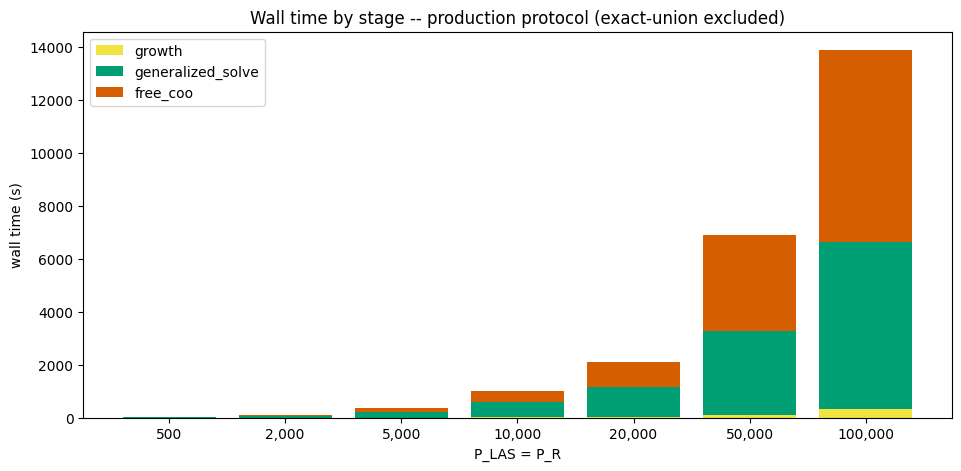

Determinant counts (production protocol, no union):
  P_R=    500: P_R_achieved=    500  free_coo_n_dets=  1,000  (union_n_dets not part of the production protocol, was 324,500 in the validation-only run)
  P_R=  2,000: P_R_achieved=  2,000  free_coo_n_dets=  4,000  (union_n_dets not part of the production protocol, was 326,000 in the validation-only run)
  P_R=  5,000: P_R_achieved=  5,000  free_coo_n_dets= 10,000  (union_n_dets not part of the production protocol, was 329,000 in the validation-only run)
  P_R= 10,000: P_R_achieved= 10,000  free_coo_n_dets= 20,000  (union_n_dets not part of the production protocol, was 334,000 in the validation-only run)
  P_R= 20,000: P_R_achieved= 20,000  free_coo_n_dets= 40,000  (union_n_dets not part of the production protocol, was 344,000 in the validation-only run)
  P_R= 50,000: P_R_achieved= 50,000  free_coo_n_dets=100,000  (union_n_dets not part of the production protocol, was 374,000 in the validation-only run)
  P_R=100,000: P_R_achieved=10

In [ ]:

stage_fields = ["growth", "generalized_solve", "free_coo"]
stage_colors = ["#F0E442", "#009E73", "#D55E00"]

wt_x = list(DIAG_ORDER)
wt_points = dict(diag_points)
for label, pt in sorted(no_union_points.items()):
    if not isinstance(pt, dict) or pt.get("skipped") or "wall_s_by_stage" not in pt:
        continue
    p_r = pt["determinants"]["P_R_requested"]
    if p_r not in wt_x:
        wt_x.append(p_r)
        wt_points[p_r] = pt
wt_x = sorted(wt_x)

fig, ax = plt.subplots(figsize=(9.5, 4.6), constrained_layout=True)
bottom = np.zeros(len(wt_x))
x = np.arange(len(wt_x))
for field, color in zip(stage_fields, stage_colors):
    vals = np.array([wt_points[p]["wall_s_by_stage"][field] for p in wt_x])
    ax.bar(x, vals, bottom=bottom, label=field, color=color)
    bottom += vals
ax.set_xticks(x); ax.set_xticklabels([f"{p:,}" for p in wt_x])
ax.set_xlabel("P_LAS = P_R"); ax.set_ylabel("wall time (s)")
ax.set_title("Wall time by stage -- production protocol (exact-union excluded)")
ax.legend()
plt.show()

print("Determinant counts (production protocol, no union):")
for p in wt_x:
    d = wt_points[p]["determinants"]
    union_note = "" if d.get("union_n_dets") is None else f", was {d['union_n_dets']:,} in the validation-only run"
    print(f"  P_R={p:>7,}: P_R_achieved={d['P_R_achieved']:>7,}  "
          f"free_coo_n_dets={d['free_coo_n_dets']:>7,}  "
          f"(union_n_dets not part of the production protocol{union_note})")




### Why the 10k point beats 20k after free COO

The apparent 10k "spike" is isolated to the **non-convex orbital-relaxation step**, not
to determinant growth. From 10k/10k to 20k/20k, the fixed-frame exact-union energy
improves normally by **1.093 mHa**, and the truncated-union starting energy improves by
**21.537 mHa**. The inversion occurs because free COO gains **73.533 mHa** at 10k but only
**30.472 mHa** at 20k, leaving the optimized 10k energy **21.524 mHa lower**.

This is not evidence for a stochastic selected-CI fluctuation: the release recovery ladder
constructs nested $P_R$ spaces and deterministic top-$K$ $P_{LAS}$ supports, and this
fixed-support COO path has no random-discovery stage. Increasing the 20k BFGS budget from
150 to 300 and 500 changes the endpoint by only **0.0022 mHa**, so extra iterations from
the same starting frame do not escape its stationary point. A same-input rerun is therefore
not expected to ``normalize'' a 21.524 mHa difference, although threaded floating-point
reductions can cause small run-to-run changes. The decisive follow-up is a controlled
multi-start or a 20k solve initialized from the optimized 10k orbital frame.

### Independent $P_{LAS}$ and $P_R$ sensitivity

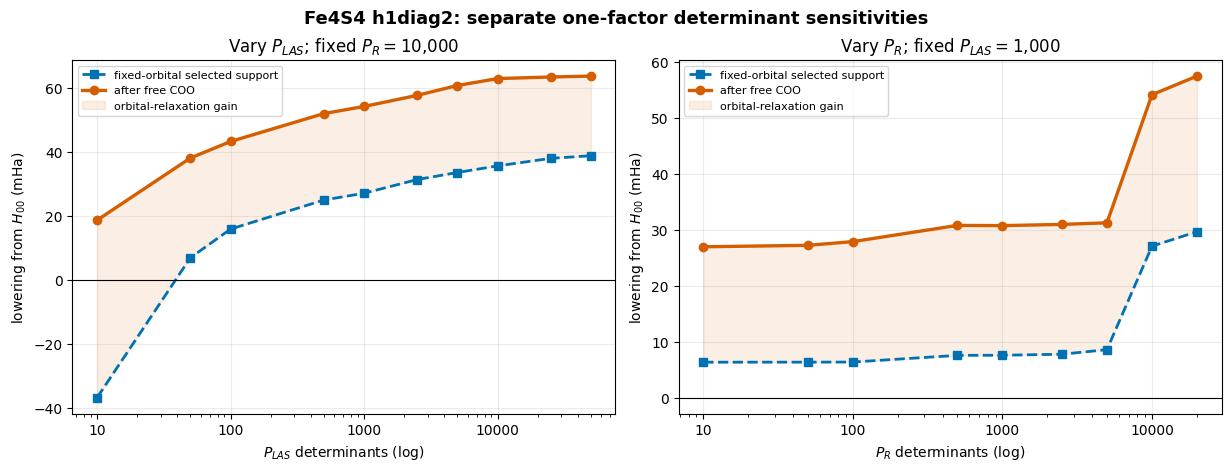

Interpretation: P_LAS gives a smooth lowering with diminishing returns. P_R is nearly flat through 5k, then adds a large improvement at 10k and a further 3.33 mHa at 20k. Because free COO is non-convex, these are empirical one-factor sensitivities, not additive P_LAS/P_R contributions.


In [ ]:
%matplotlib inline
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

one_factor_path = Path(
    "data/results/04_fe4s4_stress_test/h1diag2_one_factor_sensitivity.json"
)
one_factor = json.loads(one_factor_path.read_text())
h00_one_factor = one_factor["parent"]["h00_ha"]

plot_specs = [
    ("p_las", r"$P_{LAS}$", r"fixed $P_R=10{,}000$"),
    ("p_r", r"$P_R$", r"fixed $P_{LAS}=1{,}000$"),
]
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6), constrained_layout=True)
for ax, (axis_key, xlabel, fixed_label) in zip(axes, plot_specs):
    points = one_factor["axes"][axis_key]["points"]
    x = np.asarray([point["actual"] for point in points], dtype=float)
    fixed_frame = 1000.0 * np.asarray(
        [h00_one_factor - point["e_before_ha"] for point in points]
    )
    free_coo = 1000.0 * np.asarray(
        [h00_one_factor - point["e_after_ha"] for point in points]
    )
    ax.plot(x, fixed_frame, "s--", color="#0072B2", linewidth=2,
            label="fixed-orbital selected support")
    ax.plot(x, free_coo, "o-", color="#D55E00", linewidth=2.4,
            label="after free COO")
    ax.fill_between(x, fixed_frame, free_coo, color="#D55E00", alpha=0.10,
                    label="orbital-relaxation gain")
    ax.axhline(0.0, color="black", linewidth=0.8)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.set_xlabel(f"{xlabel} determinants (log)")
    ax.set_ylabel(r"lowering from $H_{00}$ (mHa)")
    ax.set_title(f"Vary {xlabel}; {fixed_label}")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle("Fe4S4 h1diag2: separate one-factor determinant sensitivities",
             fontsize=13, fontweight="bold")
plt.show()

## Absolute total energy versus actual support

The plot below shows the final orbital-optimized **FRASCI total energy** against the actual
combined $P_{LAS}+P_R$ determinant support. Horizontal lines show the whole-system phased
TrimCI+COO result at 20,000 determinants and the published DMRG($d=4000$) energy.

**Next controlled run.** First let the currently running 250k point finish. Then test the
orbital-basin diagnosis by initializing the 20k free-COO calculation from the optimized 10k
orbital frame, independently rediagonalizing the complete 40,000-determinant combined support
($P_{LAS}=P_R=20{,}000$) in that frame before continuing orbital optimization. Controlled
orbital multistarts are a useful secondary check;
a blind identical rerun from the original frame is not.

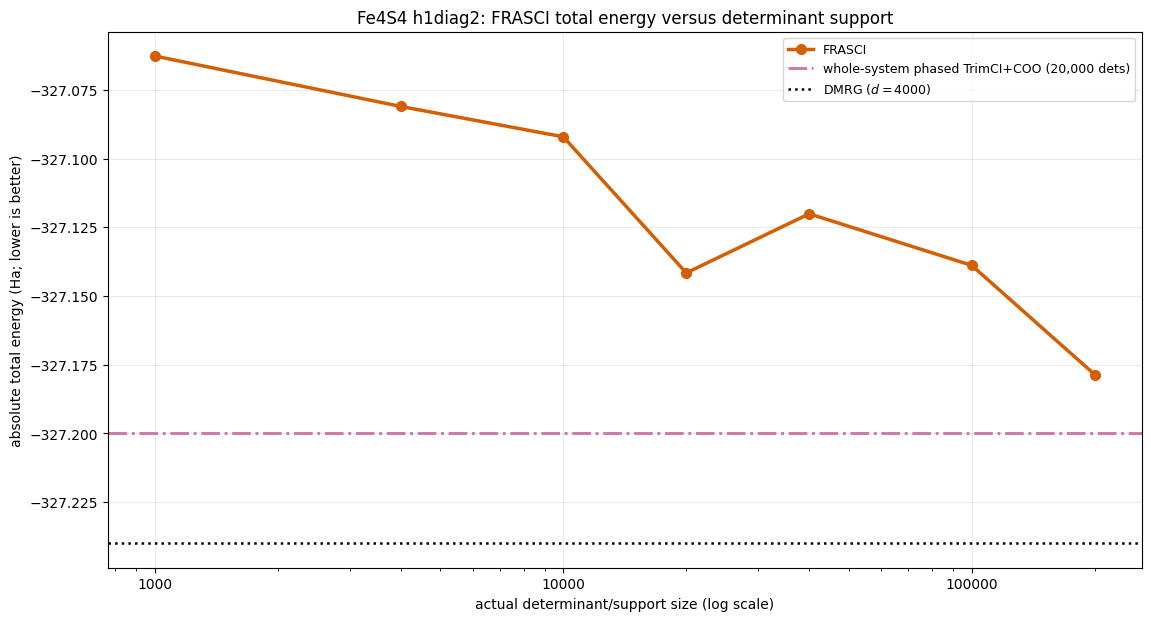

Plotted 7 completed free-COO points through 200,000 determinants of actual support.
Reference lines: whole-system phased TrimCI+COO at 20,000 determinants and published DMRG(d=4000).


In [ ]:
%matplotlib inline
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

result_dir = Path("data/results/04_fe4s4_stress_test")
joint_abs = json.loads((result_dir / "h1diag2_joint_sweep.json").read_text())
refs_abs = json.loads((result_dir / "fe4s4_energy_references.json").read_text())

# Completed diagonal points from the certified fresh parent. points_no_union is
# intentionally optional so a finished large production rung is included on re-execution.
records = []
for label, point in joint_abs["points"].items():
    if ("_BFGS" in label or point.get("skipped") or
            not label.startswith("P_LAS=") or "energies_ha" not in point):
        continue
    det = point["determinants"]
    records.append((
        det["free_coo_n_dets"], det["P_LAS_requested"], det["P_R_requested"], point
    ))
for label, point in joint_abs.get("points_no_union", {}).items():
    if point.get("skipped") or "energies_ha" not in point:
        continue
    det = point["determinants"]
    if not any(existing[0] == det["free_coo_n_dets"] for existing in records):
        records.append((
            det["free_coo_n_dets"], det["P_LAS_requested"], det["P_R_requested"], point
        ))
records.sort(key=lambda row: row[0])

support = np.asarray([row[0] for row in records], dtype=float)
post_coo = np.asarray([row[3]["energies_ha"]["free_coo_after"] for row in records])

whole = refs_abs["whole_system_trimci_current"]
dmrg = refs_abs["literature_dmrg_context"]

fig, ax = plt.subplots(figsize=(11.4, 6.1), constrained_layout=True)
ax.plot(support, post_coo, "o-", color="#D55E00", linewidth=2.5, markersize=7,
        label="FRASCI")

ax.axhline(whole["energy_ha"], color="#CC79A7", linestyle="-.", linewidth=2.1,
           label=f"whole-system phased TrimCI+COO ({whole['actual_n_dets']:,} dets)")
ax.axhline(dmrg["energy_ha"], color="black", linestyle=":", linewidth=1.8,
           label=f"DMRG ($d={dmrg['bond_dimension']}$)")

ax.set_xscale("log")
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set_xlabel("actual determinant/support size (log scale)")
ax.set_ylabel("absolute total energy (Ha; lower is better)")
ax.set_title("Fe4S4 h1diag2: FRASCI total energy versus determinant support")
ax.grid(alpha=0.25)
ax.legend(fontsize=9, loc="upper right")
plt.show()